# Density analysis
##### Make sure you have installed the required dependencies. This notebook will work with .ims, .tif and .nd2 files. It will ask you which channels are GFP and NHS and how many planes you want to include in the analysis. Then it will do a global intensity normalization (this is necessary to make the thresholding more consistent throughout the stack) and will ask you to iteratively determine the threshold parameters on a single plane until you are happy with them (you can also set user defaults). Finally, it will loop through the whole stack (or the number of slices you've set) and do the thresholding, calculate the AND result and determine the density. The final result is:
- Average per slice ratio (density)
- Whole volume ratio (density)
- A plot of density per slice number
- Representative images of the minimal density value, the maximum density value and the average density value. You can use these to validate the results.

In [7]:
import os
import numpy as np
import tifffile
import h5py
import matplotlib.pyplot as plt
from nd2reader import ND2Reader
from skimage.filters import threshold_otsu
from skimage.util import img_as_ubyte
from scipy.ndimage import gaussian_filter
from tqdm import tqdm
from IPython.display import clear_output


# --------------------- Preview Helpers ---------------------

def preview_channels_slices(slice_list):
    fig, axes = plt.subplots(1, len(slice_list), figsize=(12, 4))
    if len(slice_list) == 1:
        axes = [axes]
    for i, s in enumerate(slice_list):
        vmin, vmax = np.percentile(s, [1, 99])
        axes[i].imshow(s, cmap='gray', vmin=vmin, vmax=vmax)
        axes[i].set_title(f"Channel {i}")
        axes[i].axis('off')
    plt.tight_layout()
    plt.show()


def preview_threshold(volume, binary_volume, z_index, blurred_volume=None):
    fig, axs = plt.subplots(1, 3 if blurred_volume is not None else 2, figsize=(12, 4))
    vmin, vmax = np.percentile(volume[z_index], [1, 99])
    axs[0].imshow(volume[z_index], cmap='gray', vmin=vmin, vmax=vmax)
    axs[0].set_title("Original")
    axs[0].axis('off')

    if blurred_volume is not None:
        axs[1].imshow(blurred_volume[z_index], cmap='gray', vmin=vmin, vmax=vmax)
        axs[1].set_title("Blurred")
        axs[1].axis('off')
        bin_ax = axs[2]
    else:
        bin_ax = axs[1]

    bin_ax.imshow(binary_volume[z_index], cmap='gray')
    bin_ax.set_title("Binarized")
    bin_ax.axis('off')
    plt.tight_layout()
    plt.show()


# --------------------- Data Loading ---------------------

def load_image_dual_channel(path):
    def get_slice_indices(n_slices):
        range_input = input("Enter slice range for analysis (e.g. 10-50 or leave empty for full stack): ").strip()
        if range_input:
            try:
                z_start, z_end = map(int, range_input.split('-'))
                if not (0 <= z_start <= z_end < n_slices):
                    raise ValueError
                base_range = list(range(z_start, z_end + 1))
            except Exception:
                raise ValueError("Invalid range input. Use format like 10-50 within slice limits.")
        else:
            base_range = list(range(n_slices))

        analysis_input = input("Enter analysis interval (e.g., 1 = every slice, 10 = every 10th slice). Leave empty for every slice: ").strip()
        analysis_interval = int(analysis_input) if analysis_input else 1
        slice_indices = base_range[::analysis_interval]
        print(f"\n✅ Analyzing {len(slice_indices)} out of {len(base_range)} slices (interval = {analysis_interval})")
        return slice_indices

    ext = os.path.splitext(path)[1].lower()

    # --- TIFF ---
    if ext in ['.tif', '.tiff']:
        img = tifffile.imread(path)
        if img.ndim != 4:
            raise ValueError("Expected 4D TIFF with shape (Z,C,Y,X) or (C,Z,Y,X)")

        channel_axis = 1 if img.shape[1] <= 5 else 0
        n_channels = img.shape[channel_axis]
        n_slices = img.shape[0] if channel_axis == 1 else img.shape[1]
        mid = n_slices // 2

        slice_list = [
            img[mid, ch, :, :] if channel_axis == 1 else img[ch, mid, :, :]
            for ch in range(n_channels)
        ]

        print(f"\n📦 Detected {n_channels} channel(s) and {n_slices} Z-slices in TIFF file.")
        preview_channels_slices(slice_list)

        gfp_index = int(input("Enter the index of the GFP channel: "))
        nhs_index = int(input("Enter the index of the NHS channel: "))
        slice_indices = get_slice_indices(n_slices)

        if channel_axis == 1:
            def gfp_generator():
                for z in slice_indices:
                    yield img[z, gfp_index, :, :]

            def nhs_generator():
                for z in slice_indices:
                    yield img[z, nhs_index, :, :]
        else:
            def gfp_generator():
                for z in slice_indices:
                    yield img[gfp_index, z, :, :]

            def nhs_generator():
                for z in slice_indices:
                    yield img[nhs_index, z, :, :]

        metadata = {
            "slice_indices": slice_indices,
            "slice_start": slice_indices[0],
            "slice_end": slice_indices[-1],
            "slice_interval": slice_indices[1] - slice_indices[0] if len(slice_indices) > 1 else 1,
            "gfp_index": gfp_index,
            "nhs_index": nhs_index
        }
        return lambda: gfp_generator(), lambda: nhs_generator(), metadata

    # --- ND2 ---
    elif ext == '.nd2':
        frames = ND2Reader(path)
        if 'c' not in frames.sizes or frames.sizes['c'] < 2:
            raise ValueError("ND2 file does not contain multiple channels.")

        z_slices = frames.sizes.get('z', 1)
        channels = frames.sizes['c']
        t_index = 0
        mid_z = z_slices // 2

        slice_list = [frames.get_frame_2D(t=t_index, z=mid_z, c=c) for c in range(channels)]

        print(f"\n📦 Detected {channels} channel(s) and {z_slices} Z-slices in ND2 file.")
        preview_channels_slices(slice_list)

        gfp_index = int(input("Enter the index of the GFP channel: "))
        nhs_index = int(input("Enter the index of the NHS channel: "))
        slice_indices = get_slice_indices(z_slices)

        def gfp_generator():
            for z in slice_indices:
                yield frames.get_frame_2D(t=t_index, z=z, c=gfp_index)

        def nhs_generator():
            for z in slice_indices:
                yield frames.get_frame_2D(t=t_index, z=z, c=nhs_index)
        metadata = {
            "slice_indices": slice_indices,
            "slice_start": slice_indices[0],
            "slice_end": slice_indices[-1],
            "slice_interval": slice_indices[1] - slice_indices[0] if len(slice_indices) > 1 else 1,
            "gfp_index": gfp_index,
            "nhs_index": nhs_index
        }
        return lambda: gfp_generator(), lambda: nhs_generator(), metadata


    # --- IMS ---
    elif ext == '.ims':
        with h5py.File(path, 'r') as f_preview:
            base_path = '/DataSet/ResolutionLevel 0/TimePoint 0/'
            available_channels = [k for k in f_preview[base_path].keys() if k.startswith("Channel")]
            n_slices = f_preview[base_path + available_channels[0] + '/Data'].shape[0]
            mid = n_slices // 2

            slice_list = [f_preview[base_path + ch + '/Data'][mid, :, :] for ch in available_channels]

        print(f"\n📦 Detected {len(available_channels)} channel(s) and {n_slices} Z-slices in IMS file.")
        preview_channels_slices(slice_list)

        gfp_index = int(input("Enter the index of the GFP channel: "))
        nhs_index = int(input("Enter the index of the NHS channel: "))
        slice_indices = get_slice_indices(n_slices)

        f = h5py.File(path, 'r')  # keep open
        gfp_dataset = f[f'/DataSet/ResolutionLevel 0/TimePoint 0/{available_channels[gfp_index]}/Data']
        nhs_dataset = f[f'/DataSet/ResolutionLevel 0/TimePoint 0/{available_channels[nhs_index]}/Data']

        def gfp_generator():
            for z in slice_indices:
                yield gfp_dataset[z, :, :]

        def nhs_generator():
            for z in slice_indices:
                yield nhs_dataset[z, :, :]

        metadata = {
            "slice_indices": slice_indices,
            "slice_start": slice_indices[0],
            "slice_end": slice_indices[-1],
            "slice_interval": slice_indices[1] - slice_indices[0] if len(slice_indices) > 1 else 1,
            "gfp_index": gfp_index,
            "nhs_index": nhs_index
        }
        return lambda: gfp_generator(), lambda: nhs_generator(), metadata

    else:
        raise ValueError(f"Unsupported file format: {ext}")




# --------------------- Interactive Tuning ---------------------

def interactive_threshold_tuning(slice_gen_fn, n_slices, channel_name,
                                  default_threshold_scale=1.0,
                                  default_blur_sigma=None):
    threshold_scale = default_threshold_scale
    blur_sigma = default_blur_sigma
    mid_index = n_slices // 2

    while True:
        gen = slice_gen_fn()
        for i in range(mid_index + 1):
            img = next(gen)

        blurred = gaussian_filter(img, sigma=blur_sigma) if blur_sigma else None
        img_display = blurred if blurred is not None else img
        img_max = np.max(img_display)
        norm_img = img_as_ubyte(img_display / img_max) if img_max > 0 else np.zeros_like(img_display, dtype=np.uint8)

        t = threshold_otsu(norm_img)
        t_scaled = max(0, int(t * threshold_scale))
        binary = (norm_img > t_scaled).astype(np.uint8) * 255

        clear_output(wait=True)
        preview_threshold(np.array([img]), np.array([binary]), 0, np.array([blurred]) if blurred is not None else None)
        print(f"\n--- Thresholding {channel_name} ---")
        print(f"threshold_scale = {threshold_scale}, blur_sigma = {blur_sigma}")
        if input("Use these settings? (y/n): ").strip().lower() == 'y':
            clear_output(wait=True)
            return threshold_scale, blur_sigma

        t_input = input("New threshold scale (Enter to keep): ").strip()
        b_input = input("New blur sigma (Enter to keep): ").strip()
        if t_input: threshold_scale = float(t_input)
        if b_input:
            blur_sigma = None if b_input.lower() in ['none', '0'] else float(b_input)


# --------------------- Core Processing ---------------------

def compute_global_intensity_limits(slice_gen_fn, n_slices, sample_rate=10):
    if n_slices <= 10:
        sample_indices = list(range(n_slices))
    else:
        sample_indices = list(range(0, n_slices, max(1, n_slices // 10)))

    sampled = []
    gen = slice_gen_fn()
    for i in tqdm(range(n_slices), desc="🔎 Sampling for global intensity"):
        img = next(gen)
        if i in sample_indices:
            sampled.append(img)

    if len(sampled) < 1:
        raise RuntimeError("No slices were sampled for intensity range estimation.")

    sampled = np.stack(sampled)
    return np.percentile(sampled, [1, 99])



def normalize_generator(gen, low, high):
    for img in gen:
        img = np.clip(img, low, high)
        norm = (img - low) / (high - low) if high > low else np.zeros_like(img)
        yield img_as_ubyte(norm)


def adaptive_threshold_volume(norm_gen_fn, slice_indices, blur_sigma, threshold_scale, channel_name=""):
    print(f"\n⚙️  Adaptive thresholding for {channel_name}...")

    volume, binary_volume = [], []

    gen = norm_gen_fn()
    for z, img in tqdm(zip(slice_indices, gen), total=len(slice_indices), desc=f"⏳ {channel_name} slices"):
        if blur_sigma is not None:
            img = gaussian_filter(img, sigma=blur_sigma)
        t = threshold_otsu(img)
        binary = (img > max(0, int(t * threshold_scale))).astype(np.uint8) * 255
        volume.append(img)
        binary_volume.append(binary)

    return np.array(volume), np.array(binary_volume)





# --------------------- Metrics & Display ---------------------

def ratio_per_slice_average(gfp_bin, nhs_bin):
    per_slice_ratios = []
    and_volume = np.zeros_like(gfp_bin, dtype=np.uint8)
    for z in range(gfp_bin.shape[0]):
        g, n = gfp_bin[z] == 255, nhs_bin[z] == 255
        a = np.logical_and(g, n)
        and_volume[z] = a.astype(np.uint8) * 255
        nhs_count, and_count = np.sum(n), np.sum(a)
        ratio = and_count / nhs_count if nhs_count > 0 else 0
        per_slice_ratios.append(ratio)
    return and_volume, per_slice_ratios, np.mean(per_slice_ratios)


def ratio_whole_volume(gfp_bin, nhs_bin):
    a = np.logical_and(gfp_bin == 255, nhs_bin == 255)
    and_volume = a.astype(np.uint8) * 255
    return and_volume, np.sum(a), np.sum(nhs_bin == 255), np.sum(a) / np.sum(nhs_bin == 255)


def plot_density_per_slice(per_slice_ratios, slice_indices):
    plt.figure(figsize=(10, 4))
    plt.plot(slice_indices, per_slice_ratios, marker='o')
    plt.xlabel("Z slice (sampled)")
    plt.title("Density vs Slice Number")
    plt.ylabel("AND / NHS ratio")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


def show_key_slices(gfp_vol, nhs_vol, gfp_bin, nhs_bin, and_vol, per_slice_ratios):


    avg = np.mean(per_slice_ratios)
    indices = {
        "Lowest": int(np.argmin(per_slice_ratios)),
        "Average": int(np.argmin(np.abs(np.array(per_slice_ratios) - avg))),
        "Highest": int(np.argmax(per_slice_ratios))
    }

    fig, axs = plt.subplots(len(indices), 5, figsize=(20, 4 * len(indices)))

    for row, (label, z) in enumerate(indices.items()):
        gfp_vmin, gfp_vmax = np.percentile(gfp_vol[z], [1, 99])
        nhs_vmin, nhs_vmax = np.percentile(nhs_vol[z], [1, 99])
        ratio = per_slice_ratios[z]

        axs[row][0].imshow(gfp_vol[z], cmap='gray', vmin=gfp_vmin, vmax=gfp_vmax)
        axs[row][0].set_title(f"GFP - {label} (Z={z}, R={ratio:.3f})")

        axs[row][1].imshow(nhs_vol[z], cmap='gray', vmin=nhs_vmin, vmax=nhs_vmax)
        axs[row][1].set_title("NHS")

        axs[row][2].imshow(gfp_bin[z], cmap='gray')
        axs[row][2].set_title("GFP Binary")

        axs[row][3].imshow(nhs_bin[z], cmap='gray')
        axs[row][3].set_title("NHS Binary")

        axs[row][4].imshow(and_vol[z], cmap='gray')
        axs[row][4].set_title("AND")

        for ax in axs[row]:
            ax.axis('off')

    plt.tight_layout()
    plt.show()



# --------------------- Main Pipeline ---------------------

def process_image_adaptive(path, default_blur_sigma_gfp=None, default_blur_sigma_nhs=None,
                           default_thresh_gfp=0.75, default_thresh_nhs=0.85, sample_rate=10):
    gfp_gen_fn, nhs_gen_fn, meta = load_image_dual_channel(path)
    slice_indices = meta["slice_indices"]
    n_slices = len(slice_indices)

    
    print("\n⚙️  Computing global intensity range for GFP...")
    gfp_low, gfp_high = compute_global_intensity_limits(gfp_gen_fn, n_slices, sample_rate)
    print("\n⚙️  Computing global intensity range for NHS...")
    nhs_low, nhs_high = compute_global_intensity_limits(nhs_gen_fn, n_slices, sample_rate)

    gfp_norm_fn = lambda: normalize_generator(gfp_gen_fn(), gfp_low, gfp_high)
    nhs_norm_fn = lambda: normalize_generator(nhs_gen_fn(), nhs_low, nhs_high)

    print("\n--- Thresholding GFP channel ---")
    gfp_thresh, gfp_blur = interactive_threshold_tuning(gfp_norm_fn, n_slices, "GFP",
                                                        default_threshold_scale=default_thresh_gfp,
                                                        default_blur_sigma=default_blur_sigma_gfp)

    print("\n--- Thresholding NHS channel ---")
    nhs_thresh, nhs_blur = interactive_threshold_tuning(nhs_norm_fn, n_slices, "NHS",
                                                        default_threshold_scale=default_thresh_nhs,
                                                        default_blur_sigma=default_blur_sigma_nhs)

    gfp_vol, gfp_bin = adaptive_threshold_volume(gfp_norm_fn, slice_indices, gfp_blur, gfp_thresh, "GFP")
    nhs_vol, nhs_bin = adaptive_threshold_volume(nhs_norm_fn, slice_indices, nhs_blur, nhs_thresh, "NHS")

    and_vol, per_slice_ratios, avg_ratio = ratio_per_slice_average(gfp_bin, nhs_bin)
    _, and_count, nhs_count, whole_ratio = ratio_whole_volume(gfp_bin, nhs_bin)
    std_ratio = np.std(per_slice_ratios)

    print(f"\n[Stack Info] Total slices: {n_slices}")
    plot_density_per_slice(per_slice_ratios, slice_indices)

    print("\n---------- FINAL RESULTS ----------")
    print(f"Average of per-slice ratios: {avg_ratio:.4f} ± {std_ratio:.4f}")
    print(f"Volume-based ratio: {whole_ratio:.4f}\n")

    print("---------- SUMMARY ----------")
    print(f"Analyzed slices: {meta['slice_start']} to {meta['slice_end']} (interval = {meta['slice_interval']})")
    print(f"GFP  → channel index = {meta['gfp_index']}, threshold scale = {gfp_thresh}, blur sigma = {gfp_blur}")
    print(f"NHS  → channel index = {meta['nhs_index']}, threshold scale = {nhs_thresh}, blur sigma = {nhs_blur}")


    return {
        "per_slice_ratios": per_slice_ratios,
        "average_slice_ratio": avg_ratio,
        "std_slice_ratio": std_ratio,
        "whole_volume_and_count": and_count,
        "whole_volume_nhs_count": nhs_count,
        "whole_volume_ratio": whole_ratio,
        "and_volume_per_slice": and_vol,
        "gfp_volume": gfp_vol,
        "nhs_volume": nhs_vol,
        "gfp_binary": gfp_bin,
        "nhs_binary": nhs_bin
    }




##### --------------------- Run ---------------------



⚙️  Adaptive thresholding for GFP...


⏳ GFP slices: 100%|██████████| 11/11 [00:00<00:00, 22.19it/s]



⚙️  Adaptive thresholding for NHS...


⏳ NHS slices: 100%|██████████| 11/11 [00:00<00:00, 22.97it/s]



[Stack Info] Total slices: 11


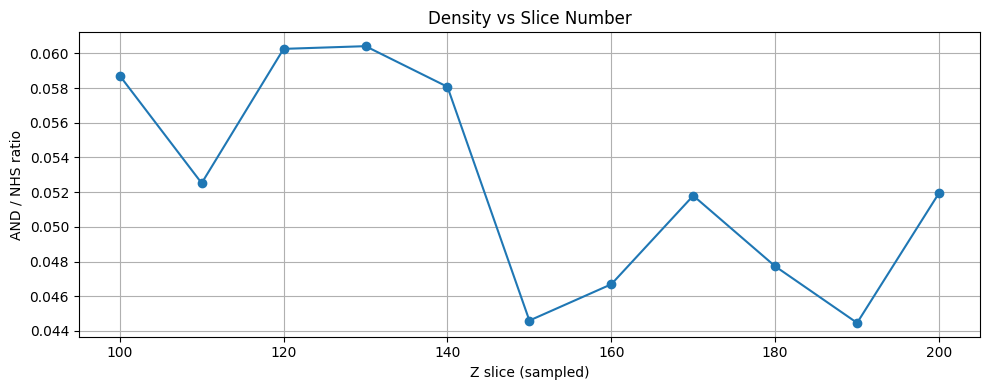


---------- FINAL RESULTS ----------
Average of per-slice ratios: 0.0525 ± 0.0059
Volume-based ratio: 0.0524

---------- SUMMARY ----------
Analyzed slices: 100 to 200 (interval = 10)
GFP  → channel index = 0, threshold scale = 0.8, blur sigma = None
NHS  → channel index = 1, threshold scale = 0.8, blur sigma = None


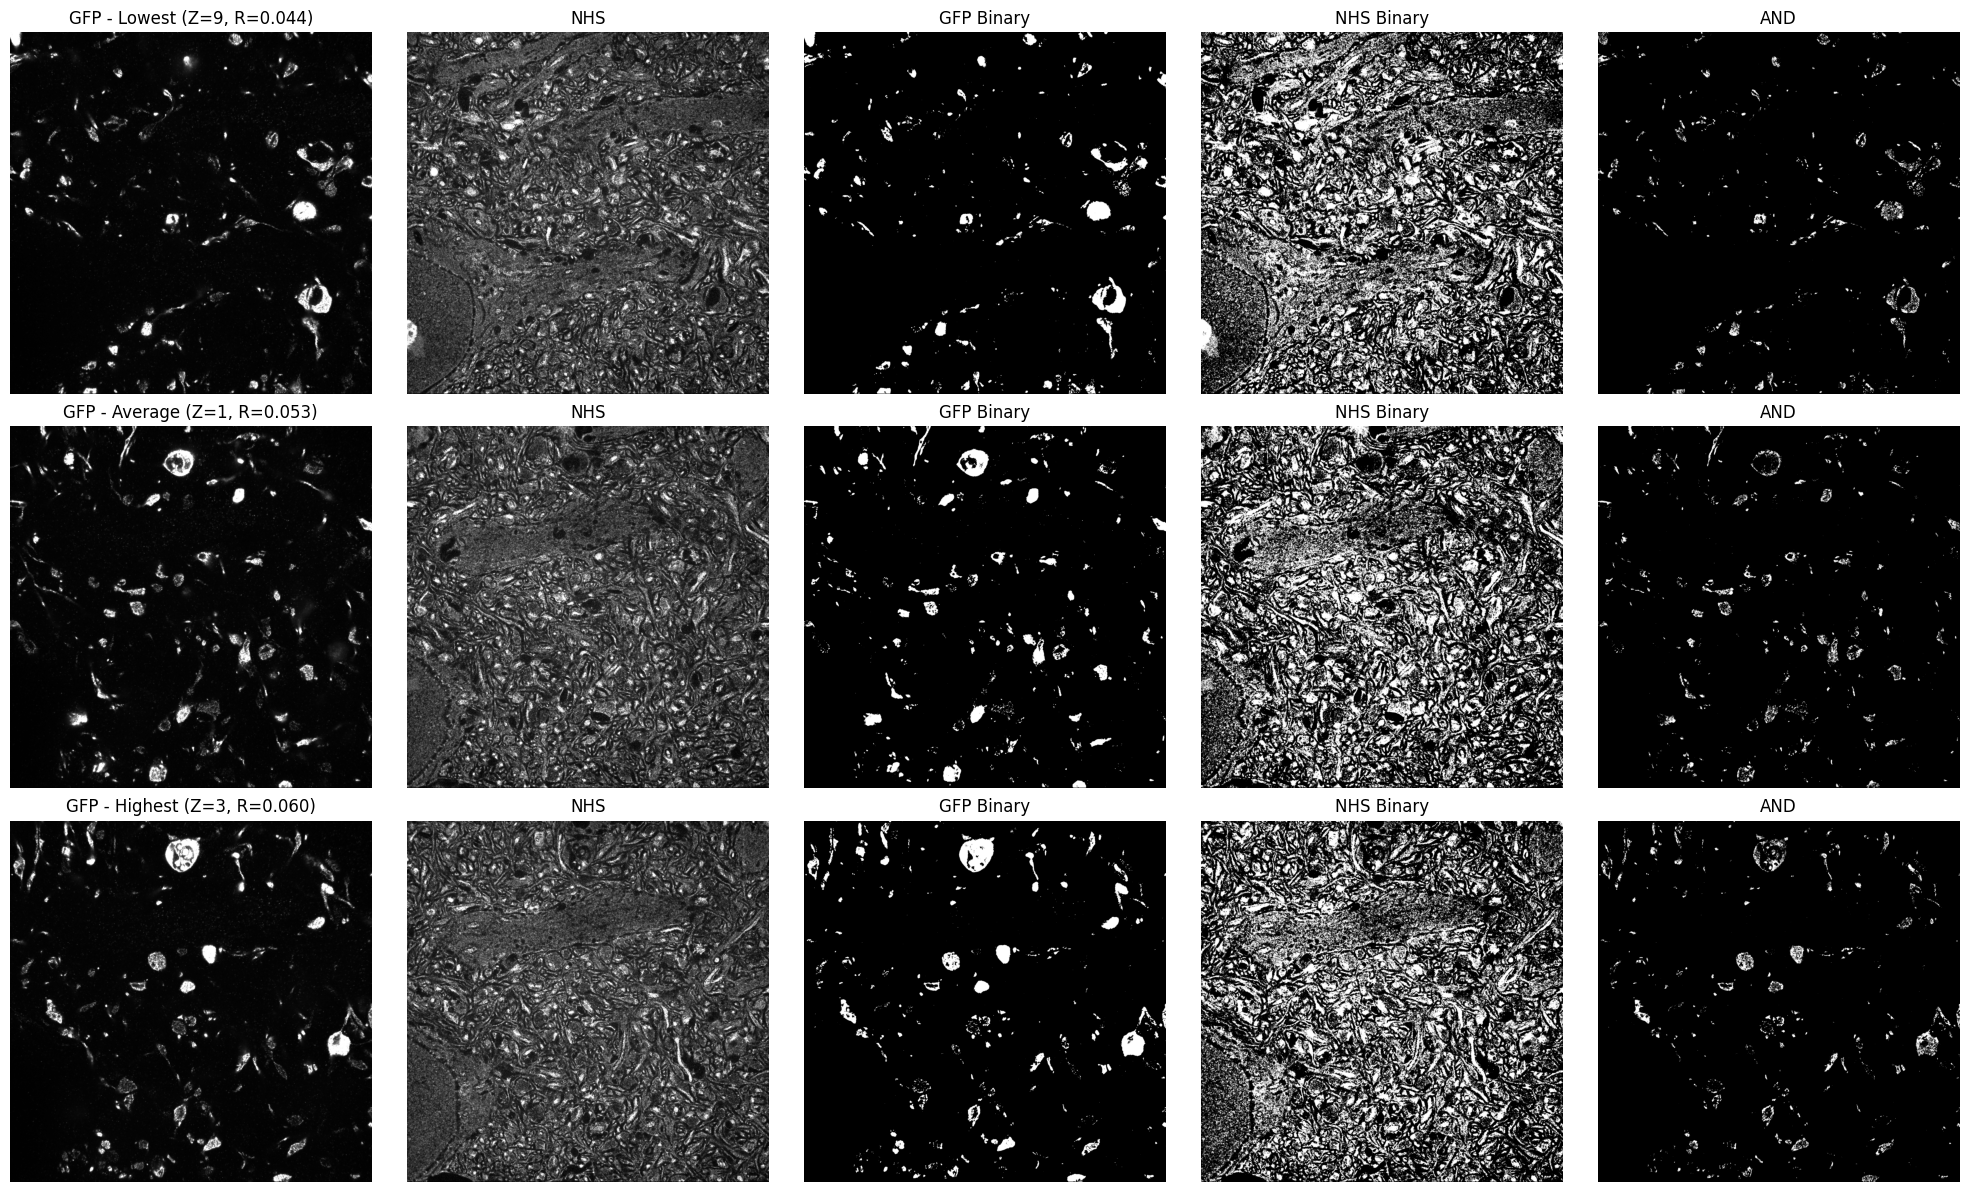

In [8]:

results = process_image_adaptive(
    "/Volumes/users/Rosa/RP182/250603-RP182-i1635-L5-A-10a1-MI-secondaries-GFP-Zstack.ims",    # Input path
    default_blur_sigma_gfp=None,                                                                # Set user default for optional blurring of GFP channel before thresholding
    default_blur_sigma_nhs=None,                                                                # Set user default for optional blurring of NHS channel before thresholding
    default_thresh_gfp=0.8,                                                                     # Set user default for thresholding GFP channel
    default_thresh_nhs=0.8                                                                            # Set user default for thresholding NHS channel
)


show_key_slices(
    results["gfp_volume"], results["nhs_volume"],
    results["gfp_binary"], results["nhs_binary"],
    results["and_volume_per_slice"], results["per_slice_ratios"]
)